In [4]:
import os
import pandas as pd

def evaluate_tray_quality(annotations):
    """
    Evaluates packaging annotations to determine if a pork rasher tray passes or fails inspection.
    
    Parameters:
        annotations (list): Detected defect labels for a tray.
        
    Returns:
        str: 'FAIL' if defects are present, otherwise 'PASS'.
    """
    defect_keywords = ['wrinkle', 'unsealed', 'twisted', 'loose', 'defect']
    
    for label in annotations:
        if any(keyword in str(label).lower() for keyword in defect_keywords):
            return "FAIL"
            
    return "PASS"

# Test evaluation logic
test_defects = ["wrinkle", "loose meat"]
print(f"Sample Tray Inspection Result: {evaluate_tray_quality(test_defects)}")

Sample Tray Inspection Result: FAIL


In [5]:
import os
import yaml
import glob

data_dir = "../data/raw"

# Check image counts
for split in ['train', 'valid', 'test']:
    img_dir = os.path.join(data_dir, split, 'images')
    images = glob.glob(os.path.join(img_dir, '*.*'))
    print(f"{split.upper()} image count: {len(images)}")

# Read defect classes
yaml_path = os.path.join(data_dir, "data.yaml")
if os.path.exists(yaml_path):
    with open(yaml_path, 'r') as f:
        data_config = yaml.safe_load(f)
    print(f"\nDefect Classes: {data_config.get('names', [])}")
    

TRAIN image count: 0
VALID image count: 0
TEST image count: 0


In [6]:
import os
import yaml
import glob

# Auto-detect folder location regardless of where notebook is saved
if os.path.exists("../data/raw"):
    data_dir = "../data/raw"
elif os.path.exists("data/raw"):
    data_dir = "data/raw"
else:
    data_dir = os.getcwd()

print(f"Using dataset directory: {os.path.abspath(data_dir)}\n")

# Check image counts with flexible extension matching
for split in ['train', 'valid', 'test']:
    img_dir = os.path.join(data_dir, split, 'images')
    if os.path.exists(img_dir):
        all_files = os.listdir(img_dir)
        images = [f for f in all_files if f.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp', '.webp'))]
        print(f"{split.upper()} image count: {len(images)}")
    else:
        print(f"Directory not found: {img_dir}")

# Read data.yaml
yaml_path = os.path.join(data_dir, "data.yaml")
if os.path.exists(yaml_path):
    with open(yaml_path, 'r') as f:
        data_config = yaml.safe_load(f)
    print(f"\nDefect Classes: {data_config.get('names', [])}")

Using dataset directory: c:\Users\kusha\OneDrive\Desktop\Shortcuts\4th Year\MMA3001\Assignment\data\raw

TRAIN image count: 3349
VALID image count: 120
TEST image count: 80

Defect Classes: ['loose-meat', 'packaging-error', 'twisted-meat', 'unsealed', 'wrinkle']


In [7]:
pip install ultralytics


  Using cached sympy-1.14.0-py3-none-any.whl.metadata (12 kB)
INFO: pip is looking at multiple versions of contourpy to determine which version is compatible with other requirements. This could take a while.
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   --------------------- ------------------ 0.8/1.4 MB 5.6 MB/s eta 0:00:01
   ----------------------------- ---------- 1.0/1.4 MB 3.9 MB/s eta 0:00:01
   ---------------------------------------- 1.4/1.4 MB 2.4 MB/s eta 0:00:00
   ---------------------------------------- 0.0/44.0 MB ? eta -:--:--
   ---------------------------------------- 0.3/44.0 MB ? eta -:--:--
   ---------------------------------------- 0.5/44.0 MB 989.2 kB/s eta 0:00:44
   ---------------------------------------- 0.5/44.0 MB 989.2 kB/s eta 0:00:44
    --------------------------------------- 0.8/44.0 MB 882.6 kB/s eta 0:00:49
    --------------------------------------- 0.8/44.0 MB 882.6 kB/s eta 0:00:49
    ----------------------------------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gensim 4.3.3 requires numpy<2.0,>=1.18.5, but you have numpy 2.5.4 which is incompatible.
numba 0.60.0 requires numpy<2.1,>=1.22,

In [11]:
import sys
!{sys.executable} -m pip install "numpy<2" "ultralytics" --force-reinstall

  Using cached ultralytics-8.4.185-py3-none-any.whl.metadata (47 kB)
  Using cached opencv_python-5.0.0.93-cp37-abi3-win_amd64.whl.metadata (20 kB)
  Using cached torch-2.14.1-cp312-cp312-win_amd64.whl.metadata (38 kB)
  Using cached torchvision-0.29.1-cp312-cp312-win_amd64.whl.metadata (5.7 kB)
  Using cached polars-2.0.0-py3-none-any.whl.metadata (11 kB)
  Using cached nvidia_ml_py-13.615.71-py3-none-any.whl.metadata (9.7 kB)
  Using cached ultralytics_thop-2.2.3-py3-none-any.whl.metadata (14 kB)
  Using cached ultralytics_platform-0.1.94-py3-none-any.whl.metadata (17 kB)
  Using cached contourpy-1.4.0-cp312-cp312-win_amd64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
INFO: pip is looking at multiple versions of opencv-python to determine which version is compatible with other requirements. This could take a while.
  Using cached polars_runtime_32-2.0.0-cp310-abi3-win_amd64.whl.metadata (1.5 kB)
  Using cached setuptools-84.2.1-py3-none-any.wh

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  You can safely remove it manually.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to

In [13]:
import os
from ultralytics import YOLO

# Auto-detect absolute path to data.yaml
if os.path.exists("data/raw/data.yaml"):
    yaml_path = os.path.abspath("data/raw/data.yaml")
elif os.path.exists("../data/raw/data.yaml"):
    yaml_path = os.path.abspath("../data/raw/data.yaml")

# Load lightweight pretrained model
model = YOLO('yolov8n.pt')

# Train model
results = model.train(
    data=yaml_path,
    epochs=15,             # Fast convergence to meet deadline
    imgsz=540,             # Matches tray image resolution
    batch=16,
    name='pork_tray_inspection',
    workers=2
)

Ultralytics 8.4.185  Python-3.12.7 torch-2.14.1+cpu CPU (AMD Ryzen 9 8945HS w/ Radeon 780M Graphics)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=c:\Users\kusha\OneDrive\Desktop\Shortcuts\4th Year\MMA3001\Assignment\data\raw\data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=15, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=540, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_

In [16]:
import os
import glob

# Search entire workspace for any best.pt or last.pt files
pt_files = glob.glob('**/*.pt', recursive=True) + glob.glob('../**/*.pt', recursive=True)

print("Found weight files:")
for f in pt_files:
    print(os.path.abspath(f))


Found weight files:
c:\Users\kusha\OneDrive\Desktop\Shortcuts\4th Year\MMA3001\Assignment\yolov8n.pt
c:\Users\kusha\OneDrive\Desktop\Shortcuts\4th Year\MMA3001\Assignment\yolov8n.pt


In [18]:
import os
import glob

# Search standard YOLO default run locations
search_paths = [
    '**/runs/**/*.pt',
    '../**/runs/**/*.pt',
    os.path.expanduser('~/runs/**/*.pt'),
    'C:/Users/kusha/runs/**/*.pt'
]

found_weights = []
for path in search_paths:
    found_weights.extend(glob.glob(path, recursive=True))

found_weights = list(set([os.path.abspath(f) for f in found_weights]))

print("Found trained weight files:")
for weight in found_weights:
    print(weight)

Found trained weight files:
C:\Users\kusha\runs\detect\pork_tray_inspection-2\weights\last.pt
C:\Users\kusha\runs\detect\pork_tray_inspection-2\weights\best.pt


In [19]:
import os
import glob
from ultralytics import YOLO

# 1. Load your best trained model using the exact path found
weights_path = r"C:\Users\kusha\runs\detect\pork_tray_inspection-2\weights\best.pt"
model = YOLO(weights_path)

# 2. Grab all test images
test_images = glob.glob('data/raw/test/images/*.*') + glob.glob('../data/raw/test/images/*.*')

correct = 0
total = len(test_images)

for img_path in test_images:
    # Check ground truth label (txt file present and non-empty -> FAIL, else -> PASS)
    label_path = img_path.replace('images', 'labels').rsplit('.', 1)[0] + '.txt'
    actual_status = "FAIL" if (os.path.exists(label_path) and os.path.getsize(label_path) > 0) else "PASS"
    
    # Run prediction
    results = model(img_path, verbose=False)
    predicted_status = "FAIL" if len(results[0].boxes) > 0 else "PASS"
    
    if actual_status == predicted_status:
        correct += 1

if total > 0:
    accuracy = (correct / total) * 100
    print(f"Final Test Set Classification Accuracy: {accuracy:.2f}%")
else:
    print("No test images found. Please check your data/raw/test/images path.")

Final Test Set Classification Accuracy: 83.75%


In [20]:
import os
import glob

run_dir = r"C:\Users\kusha\runs\detect\pork_tray_inspection-2"
png_files = glob.glob(os.path.join(run_dir, "*.png")) + glob.glob(os.path.join(run_dir, "*.jpg"))

print("Available training plot files:")
for f in sorted(png_files):
    print(" -", os.path.basename(f))

Available training plot files:
 - BoxF1_curve.png
 - BoxPR_curve.png
 - BoxP_curve.png
 - BoxR_curve.png
 - confusion_matrix.png
 - confusion_matrix_normalized.png
 - labels.jpg
 - results.png
 - train_batch0.jpg
 - train_batch1.jpg
 - train_batch1050.jpg
 - train_batch1051.jpg
 - train_batch1052.jpg
 - train_batch2.jpg
 - val_batch0_labels.jpg
 - val_batch0_pred.jpg
 - val_batch1_labels.jpg
 - val_batch1_pred.jpg
 - val_batch2_labels.jpg
 - val_batch2_pred.jpg


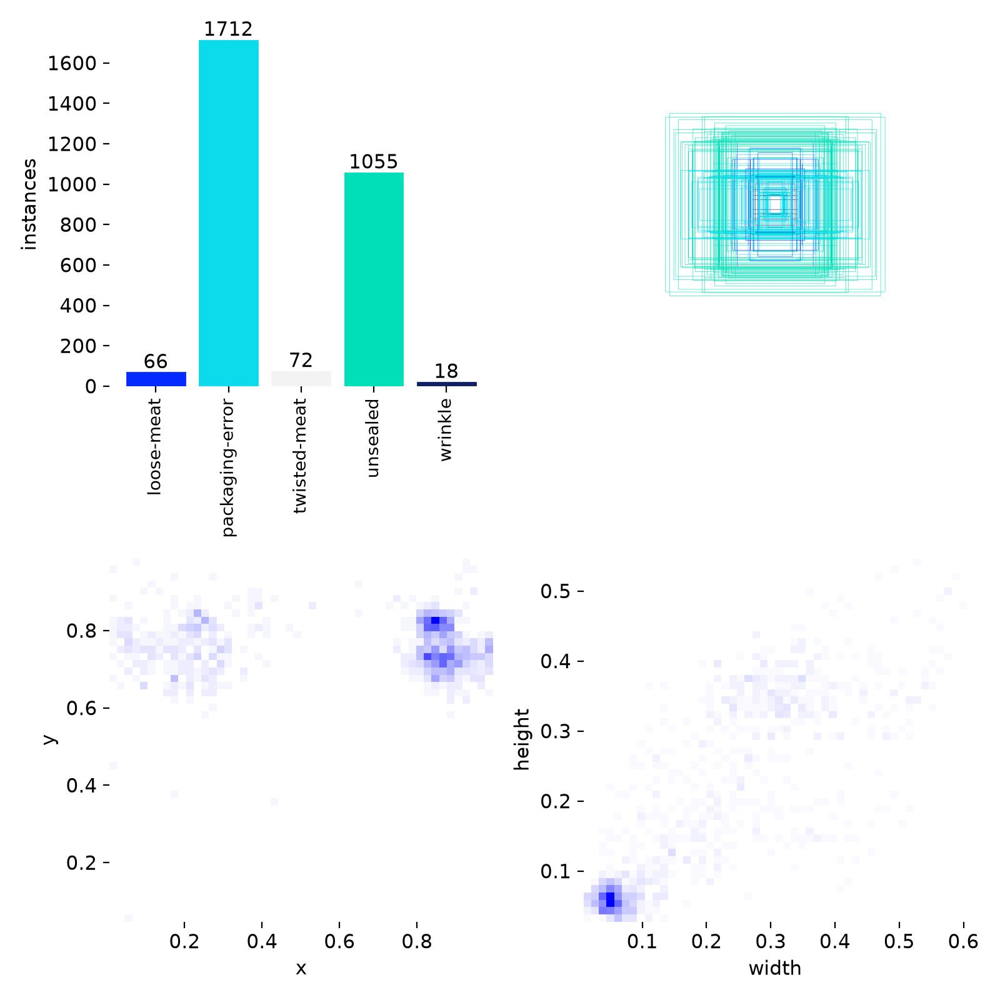

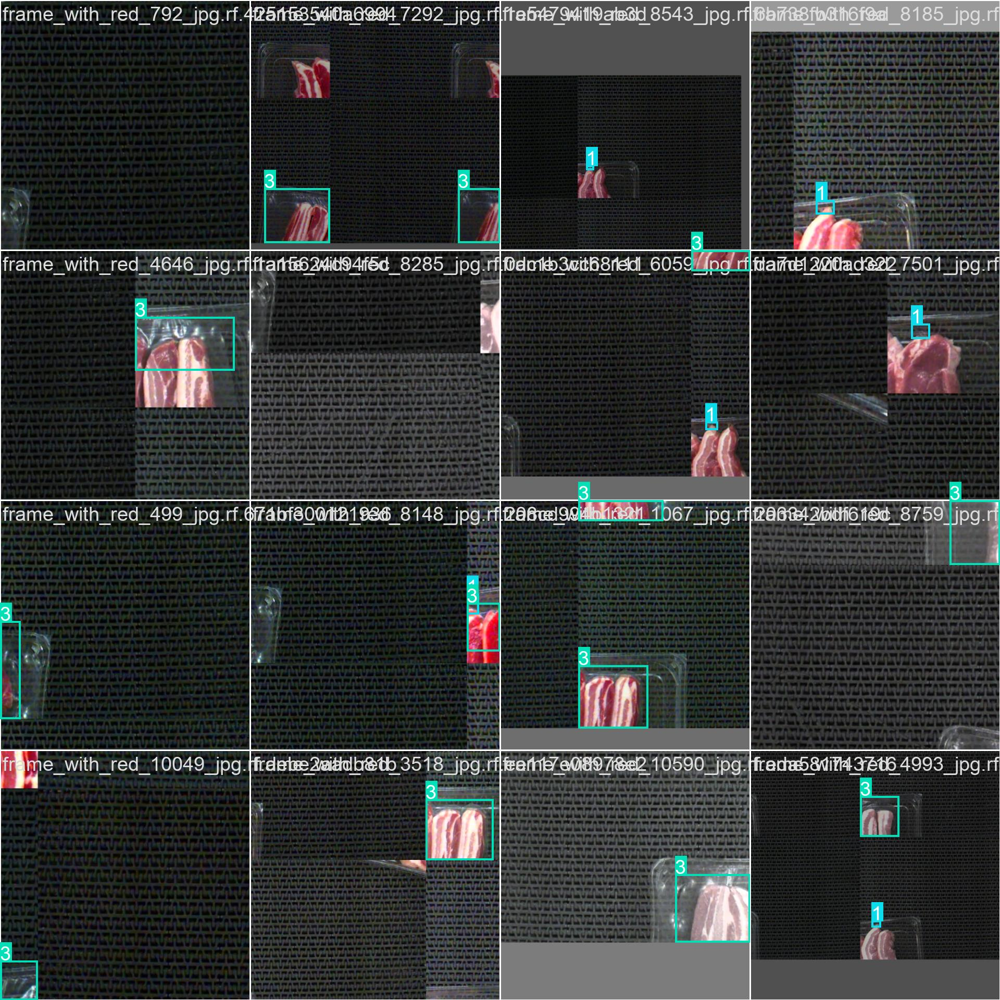

In [21]:
from PIL import Image
import os

run_dir = r"C:\Users\kusha\runs\detect\pork_tray_inspection-2"

# View labels.jpg
display(Image.open(os.path.join(run_dir, "labels.jpg")))

# View sample annotated batch
display(Image.open(os.path.join(run_dir, "train_batch0.jpg")))

Successfully copied to: figures\fig_2_1_model_predictions.jpg


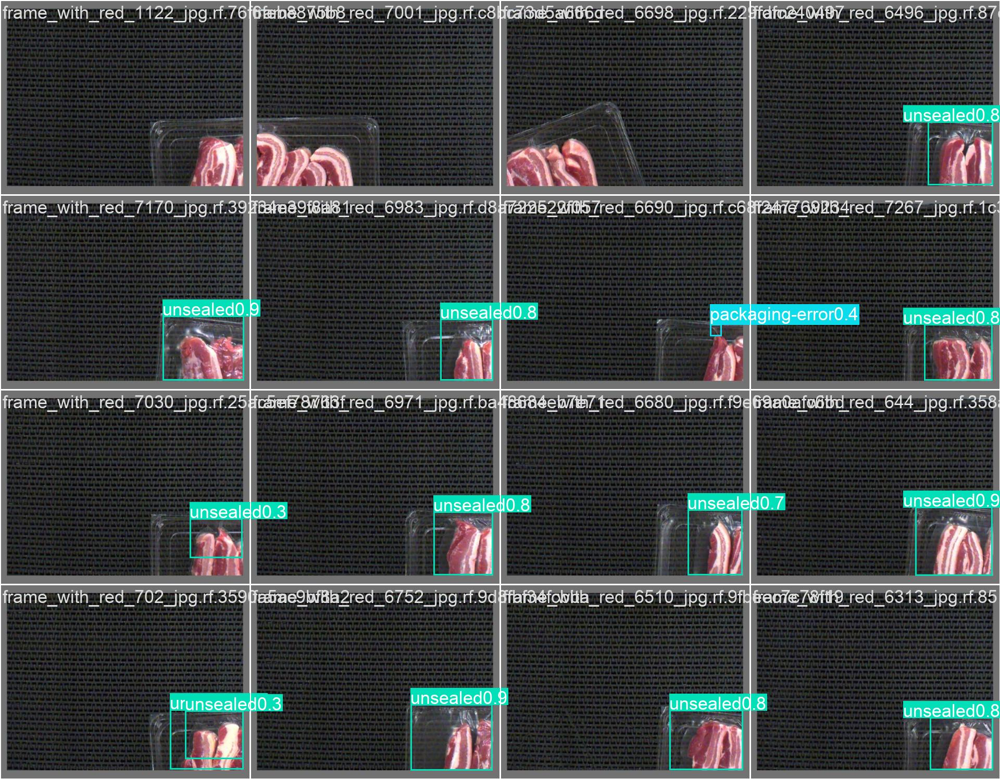

In [22]:
import os
import shutil
from PIL import Image

# Define paths
run_dir = r"C:\Users\kusha\runs\detect\pork_tray_inspection-2"
output_dir = "figures"
os.makedirs(output_dir, exist_ok=True)

# Image file name
pred_image_name = "val_batch0_pred.jpg"
src_path = os.path.join(run_dir, pred_image_name)
dst_path = os.path.join(output_dir, "fig_2_1_model_predictions.jpg")

# Copy file to figures directory
if os.path.exists(src_path):
    shutil.copy(src_path, dst_path)
    print(f"Successfully copied to: {dst_path}")
    
    # Display the image in notebook
    display(Image.open(dst_path))
else:
    print(f"File not found at: {src_path}")

Exported: figures\fig_3_1_data_augmentation.jpg


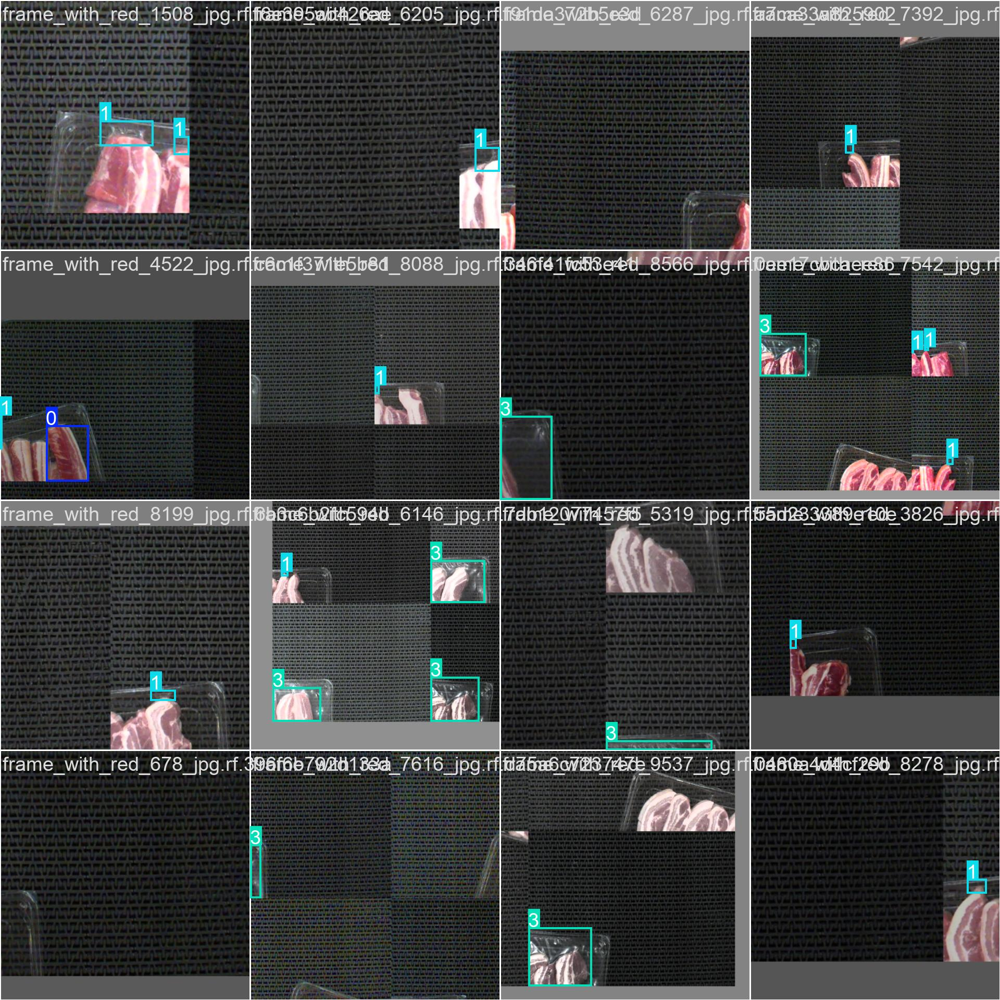

Exported: figures\fig_3_2_training_loss_curves.png


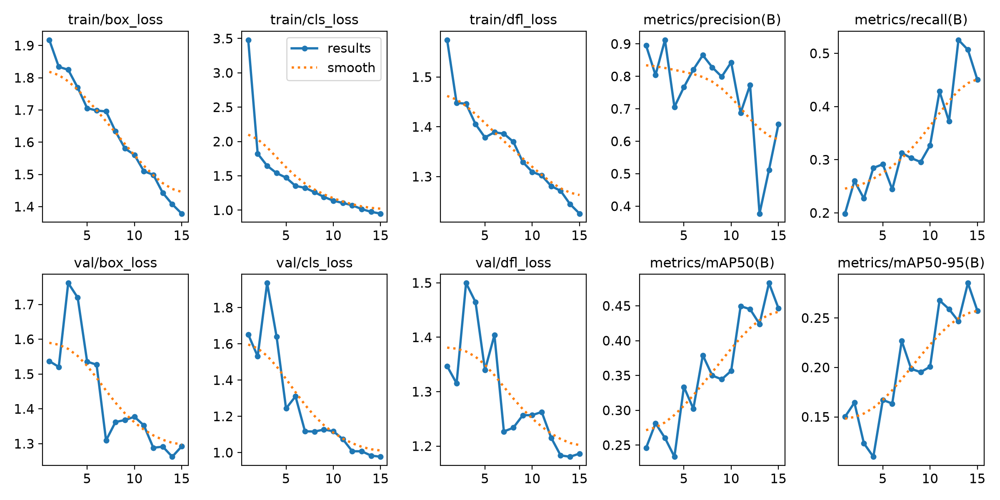

In [23]:
import os
import shutil
from PIL import Image

run_dir = r"C:\Users\kusha\runs\detect\pork_tray_inspection-2"
output_dir = "figures"
os.makedirs(output_dir, exist_ok=True)

fig_mappings = {
    "train_batch1.jpg": "fig_3_1_data_augmentation.jpg",
    "results.png": "fig_3_2_training_loss_curves.png"
}

for src_file, dst_file in fig_mappings.items():
    src_path = os.path.join(run_dir, src_file)
    dst_path = os.path.join(output_dir, dst_file)
    
    if os.path.exists(src_path):
        shutil.copy(src_path, dst_path)
        print(f"Exported: {dst_path}")
        display(Image.open(dst_path))
    else:
        print(f"Warning: {src_file} not found in {run_dir}")

Exported: figures\fig_5_1_confusion_matrix.png


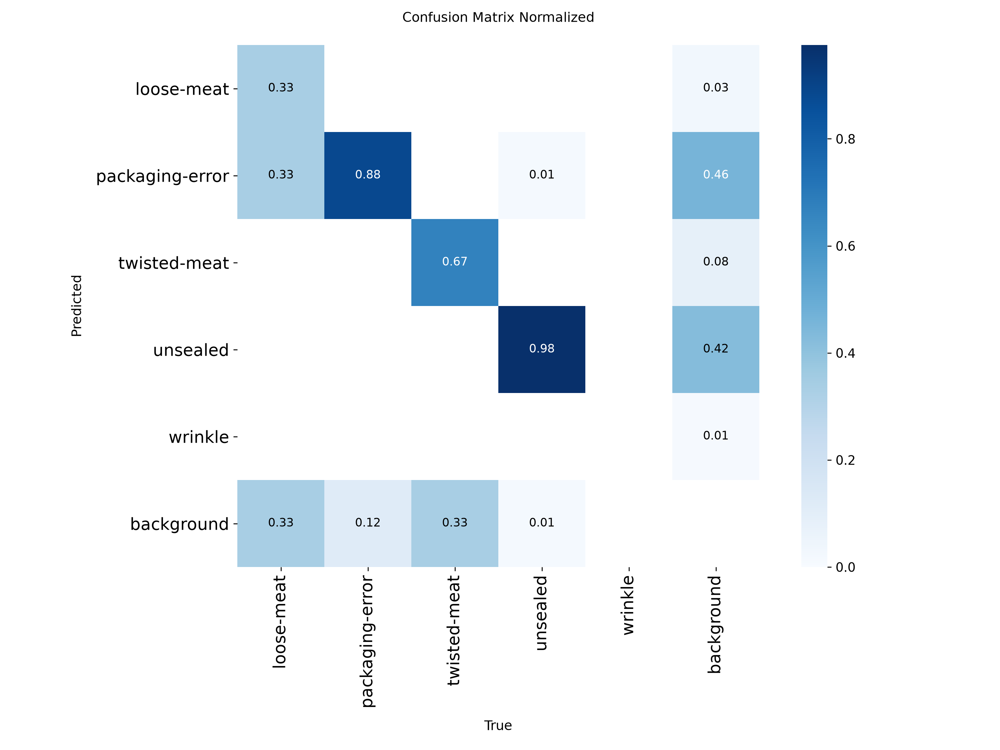

Exported: figures\fig_5_2_precision_recall_curve.png


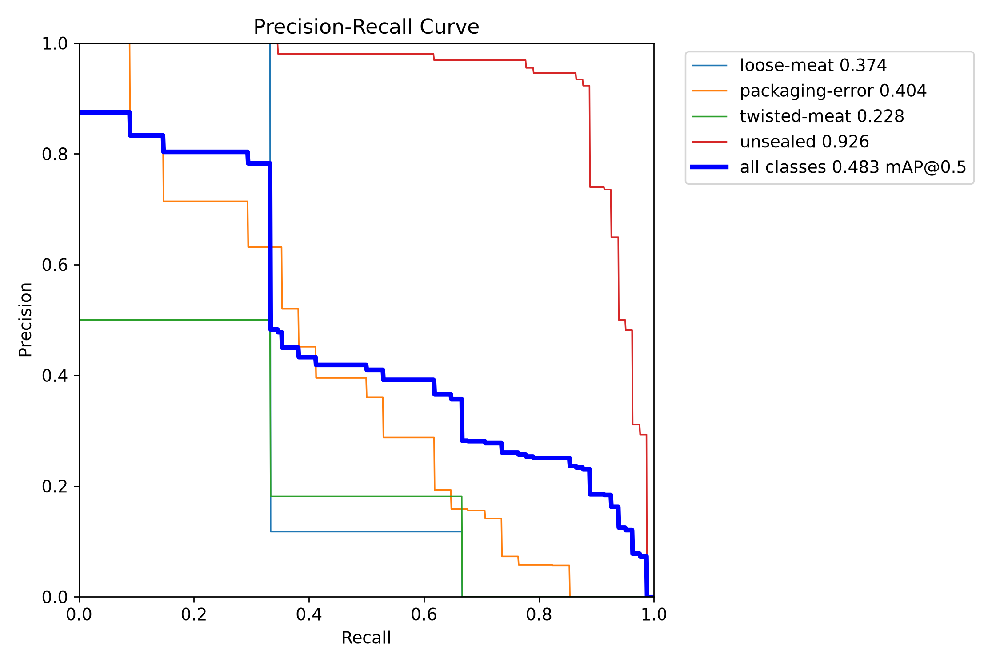

Exported: figures\fig_5_3_validation_predictions.jpg


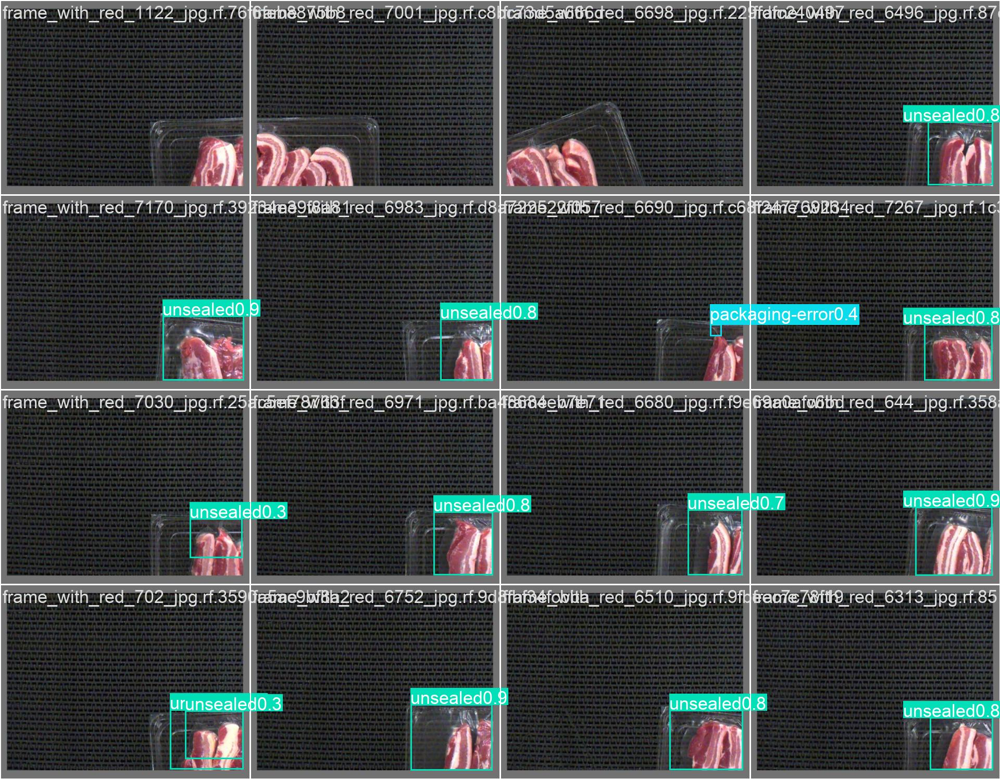

Exported: figures\fig_5_4_validation_labels.jpg


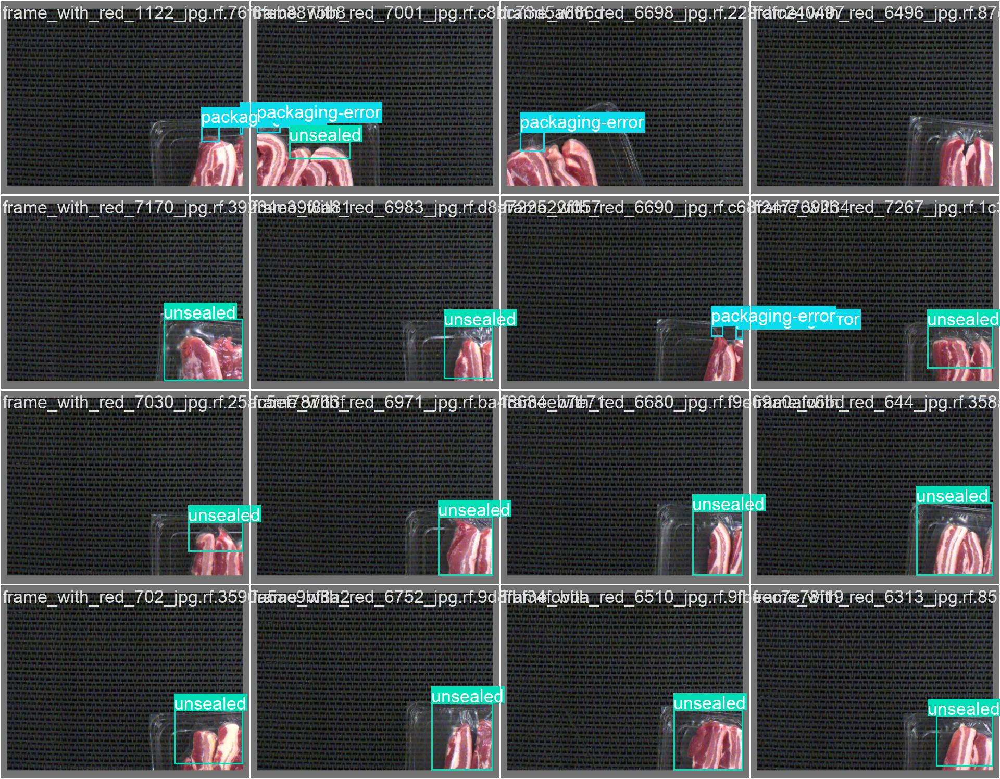

In [24]:
import os
import shutil
from PIL import Image

run_dir = r"C:\Users\kusha\runs\detect\pork_tray_inspection-2"
output_dir = "figures"
os.makedirs(output_dir, exist_ok=True)

fig_mappings = {
    "confusion_matrix_normalized.png": "fig_5_1_confusion_matrix.png",
    "BoxPR_curve.png": "fig_5_2_precision_recall_curve.png",
    "val_batch0_pred.jpg": "fig_5_3_validation_predictions.jpg",
    "val_batch0_labels.jpg": "fig_5_4_validation_labels.jpg"
}

for src_file, dst_file in fig_mappings.items():
    src_path = os.path.join(run_dir, src_file)
    dst_path = os.path.join(output_dir, dst_file)
    
    if os.path.exists(src_path):
        shutil.copy(src_path, dst_path)
        print(f"Exported: {dst_path}")
        display(Image.open(dst_path))
    else:
        print(f"Warning: {src_file} not found in {run_dir}")